In [1]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images


In [2]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [4]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# MobileNet with Adaboost

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



########## SEED = 2622715460 ##########

Saved split indices: 2720 train / 480 val


100%|██████████| 43/43 [00:19<00:00,  2.17it/s]


Epoch [1/50] Train Loss: 0.4662 (CE: 0.5753, Dice: 0.3572), Train Acc: 0.6757 | Val Loss: 0.5051 (CE: 0.6159, Dice: 0.3943), Val Acc: 0.5854
  -> Saving best model (Val Accuracy: 0.5854)


100%|██████████| 43/43 [00:20<00:00,  2.13it/s]


...

Epoch [18/50] Train Loss: 0.3895 (CE: 0.4678, Dice: 0.3112), Train Acc: 0.7316 | Val Loss: 0.5442 (CE: 0.6700, Dice: 0.4184), Val Acc: 0.5792
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.18it/s]
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epoch [19/50] Train Loss: 0.3905 (CE: 0.4733, Dice: 0.3077), Train Acc: 0.7430 | Val Loss: 0.4416 (CE: 0.5179, Dice: 0.3654), Val Acc: 0.7063
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 19. Best Val Accuracy: 0.7208
Saved model weights -> /kaggle/working/mobilenetv2_final_weights.pth

Extracting MobileNetV2 features...


Extracting Features: 100%|██████████| 23/23 [00:06<00:00,  3.69it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_final.joblib

AdaBoost Validation Accuracy: 0.6729
AdaBoost Test Accuracy: 0.9401

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9401
AdaBoost Test Precision (weighted): 0.9396
AdaBoost Test Recall (weighted): 0.9401
AdaBoost Test F1-score (weighted): 0.9395

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9480    0.9696    0.9586      1052
  Appears normal     0.9184    0.8654    0.8911       416

        accuracy                         0.9401      1468
       macro avg     0.9332    0.9175    0.9249      1468
    weighted avg     0.9396    0.9401    0.9395      1468



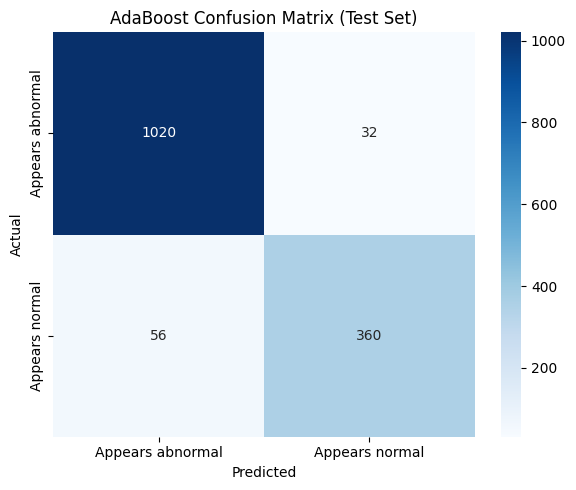


Final MobileNetV2 Test Loss: 0.3904 (CE: 0.2540, Dice: 0.5267), Final MobileNetV2 Test Accuracy: 0.9244

MobileNetV2 Test Precision (weighted): 0.9257
MobileNetV2 Test Recall (weighted): 0.9244
MobileNetV2 Test F1-score (weighted): 0.9220

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9182    0.9819    0.9490      1052
  Appears normal     0.9446    0.7788    0.8538       416

        accuracy                         0.9244      1468
       macro avg     0.9314    0.8804    0.9014      1468
    weighted avg     0.9257    0.9244    0.9220      1468



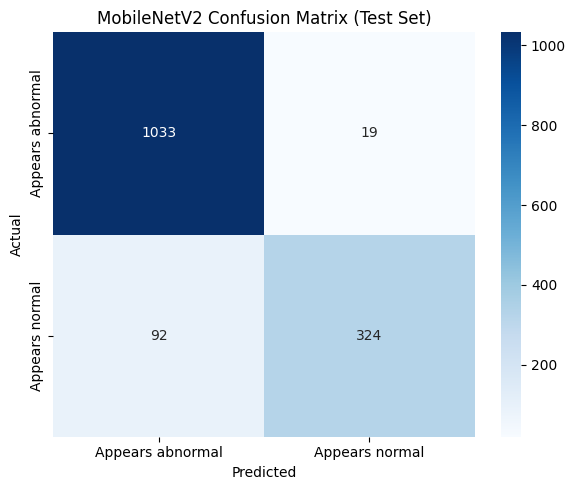

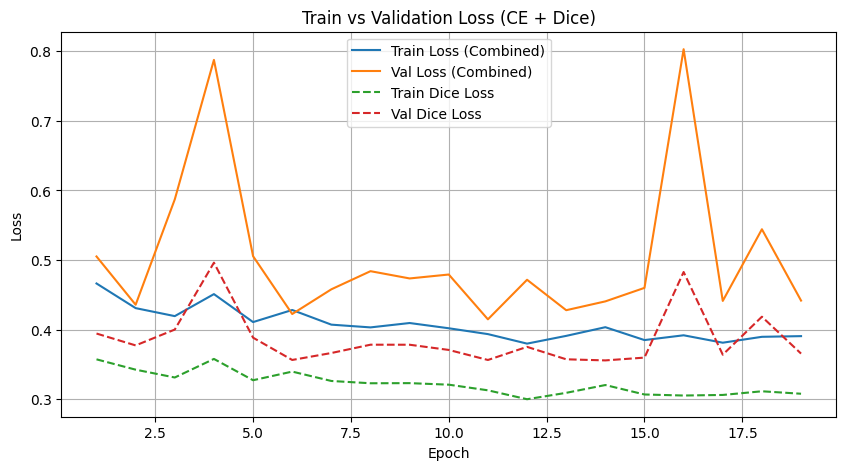

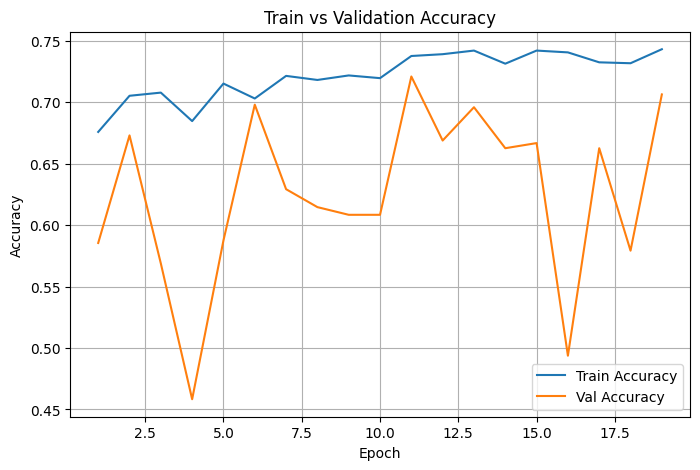


================ FINAL SUMMARY ================
Seed: 2622715460
Best MobileNetV2 Val Accuracy: 0.7208
MobileNetV2 Test Accuracy: 0.9244
MobileNetV2 Test Precision: 0.9257
MobileNetV2 Test Recall: 0.9244
MobileNetV2 Test F1-score: 0.9220
MobileNetV2 Test Dice Loss: 0.5267

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6729
AdaBoost Test Accuracy: 0.9401
AdaBoost Test Precision: 0.9396
AdaBoost Test Recall: 0.9401
AdaBoost Test F1-score: 0.9395


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import json
import joblib
import random
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns


# ============================================================
# Fixed seed (single run)
# ============================================================
seed = 2622715460
print(f"\n########## SEED = {seed} ##########\n")

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# Device configuration
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'
OUT_DIR = '/kaggle/working'


# ============================================================
# Image transformations
# ============================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================
val_size = int(0.15 * len(train_dataset))

train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Save train / val indices (does not change any results)
# ============================================================
split_info = {
    "seed": seed,
    "val_fraction": 0.15,
    "classes": train_dataset.classes,
    "class_to_idx": train_dataset.class_to_idx,
    "train_indices": [int(i) for i in train_subset.indices],
    "val_indices": [int(i) for i in val_subset.indices],
    "train_files": [train_dataset.samples[i][0] for i in train_subset.indices],
    "val_files": [train_dataset.samples[i][0] for i in val_subset.indices],
}
with open(os.path.join(OUT_DIR, "split_indices.json"), "w") as f:
    json.dump(split_info, f)
print(f"Saved split indices: {len(train_subset.indices)} train / {len(val_subset.indices)} val")


# ============================================================
# Count samples per class within train_subset
# ============================================================
train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(
    train_targets
)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


# ============================================================
# Weighted Random Sampler
# ============================================================
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================
train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained MobileNetV2
# ============================================================
mobilenet = models.mobilenet_v2(
    pretrained=True
)

num_classes = len(
    train_dataset.classes
)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================
class CombinedLoss(nn.Module):

    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
# ============================================================
optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate MobileNetV2
# ============================================================
def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================
def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================
best_accuracy = 0.0

best_model_path = "Mobilenet_1410=.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


# ============================================================
# Lists for graphs
# ============================================================
train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# MobileNetV2 Training
# ============================================================
for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = mobilenet(images)

        loss, ce, dice = criterion(outputs, labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)

        total_train += labels.size(0)

        correct_train += (predicted == labels).sum().item()

    train_accuracy = correct_train / total_train

    n_batches = len(train_loader)

    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    # ---------------- Validation ----------------
    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        mobilenet,
        val_loader
    )

    # ---------------- Store values for graphs ----------------
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)
    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)
    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    # ---------------- Print epoch results ----------------
    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, '
        f'Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, '
        f'Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # ---------------- Early stopping logic ----------------
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(mobilenet.state_dict(), best_model_path)

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at '
            f'epoch {epoch+1}. '
            f'Best Val Accuracy: {best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best MobileNetV2 model
# ============================================================
best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# Save final trained MobileNetV2 weights (does not change results)
# ============================================================
final_weights_path = os.path.join(OUT_DIR, "mobilenetv2_final_weights.pth")
torch.save({
    "state_dict": best_mobilenet_model.state_dict(),
    "num_classes": num_classes,
    "classes": train_dataset.classes,
    "class_to_idx": train_dataset.class_to_idx,
    "best_val_accuracy": best_accuracy,
    "seed": seed,
    "input_size": 224,
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
}, final_weights_path)
print("Saved model weights ->", final_weights_path)


# ============================================================
# ADABOOST
# MobileNetV2 Feature Extraction + AdaBoost
# ============================================================
def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader, desc="Extracting Features"):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(x, (1, 1))

            # Flatten
            x = torch.flatten(x, 1)

            features.extend(x.cpu().numpy())

            labels_list.extend(labels.numpy())

    return (
        np.array(features),
        np.array(labels_list)
    )


print("\nExtracting MobileNetV2 features...")

train_features, train_labels = extract_features(best_mobilenet_model, train_loader)

val_features, val_labels = extract_features(best_mobilenet_model, val_loader)

test_features, test_labels = extract_features(best_mobilenet_model, test_loader)

print("\nFeature shape:", train_features.shape)


# ============================================================
# Train AdaBoost
# ============================================================
adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=seed
)

print("\nTraining AdaBoost...")

adaboost_model.fit(train_features, train_labels)

# Save trained AdaBoost (does not change results)
adaboost_path = os.path.join(OUT_DIR, "adaboost_final.joblib")
joblib.dump(adaboost_model, adaboost_path)
print("Saved AdaBoost ->", adaboost_path)


# ============================================================
# AdaBoost Validation
# ============================================================
adaboost_val_preds = adaboost_model.predict(val_features)

adaboost_val_accuracy = np.mean(adaboost_val_preds == val_labels)

print(f"\nAdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}")


# ============================================================
# AdaBoost Test Predictions
# ============================================================
adaboost_test_preds = adaboost_model.predict(test_features)

adaboost_test_accuracy = np.mean(adaboost_test_preds == test_labels)

print(f"AdaBoost Test Accuracy: {adaboost_test_accuracy:.4f}")


# ============================================================
# AdaBoost Metrics
# ============================================================
class_names = train_dataset.classes

adaboost_accuracy = np.mean(adaboost_test_preds == test_labels)

adaboost_precision = precision_score(
    test_labels, adaboost_test_preds, average='weighted', zero_division=0
)

adaboost_recall = recall_score(
    test_labels, adaboost_test_preds, average='weighted', zero_division=0
)

adaboost_f1 = f1_score(
    test_labels, adaboost_test_preds, average='weighted', zero_division=0
)

print("\n---------------- AdaBoost Metrics ----------------")
print(f"AdaBoost Test Accuracy: {adaboost_accuracy:.4f}")
print(f"AdaBoost Test Precision (weighted): {adaboost_precision:.4f}")
print(f"AdaBoost Test Recall (weighted): {adaboost_recall:.4f}")
print(f"AdaBoost Test F1-score (weighted): {adaboost_f1:.4f}")


# ============================================================
# AdaBoost Classification Report
# ============================================================
print("\nAdaBoost Per-class report:")

print(
    classification_report(
        test_labels,
        adaboost_test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# AdaBoost Confusion Matrix
# ============================================================
adaboost_cm = confusion_matrix(test_labels, adaboost_test_preds)

plt.figure(figsize=(6, 5))

sns.heatmap(
    adaboost_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('AdaBoost Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()


# ============================================================
# ORIGINAL MOBILENETV2 TEST EVALUATION
# ============================================================
test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal MobileNetV2 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, '
    f'Dice: {test_dice:.4f}), '
    f'Final MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# MobileNetV2 Test Metrics
# ============================================================
true_labels, pred_labels = get_predictions(best_mobilenet_model, test_loader)

precision = precision_score(true_labels, pred_labels, average='weighted', zero_division=0)

recall = recall_score(true_labels, pred_labels, average='weighted', zero_division=0)

f1 = f1_score(true_labels, pred_labels, average='weighted', zero_division=0)

print(f'\nMobileNetV2 Test Precision (weighted): {precision:.4f}')
print(f'MobileNetV2 Test Recall (weighted): {recall:.4f}')
print(f'MobileNetV2 Test F1-score (weighted): {f1:.4f}')


# ============================================================
# MobileNetV2 Classification Report
# ============================================================
print('\nMobileNetV2 Per-class report:')

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================
cm = confusion_matrix(true_labels, pred_labels)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('MobileNetV2 Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
plt.plot(epochs_range, val_losses, label='Val Loss (Combined)')
plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss (CE + Dice)')
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_accs, label='Train Accuracy')
plt.plot(epochs_range, val_accs, label='Val Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================
print('\n================ FINAL SUMMARY ================')
print(f'Seed: {seed}')
print(f'Best MobileNetV2 Val Accuracy: {best_accuracy:.4f}')
print(f'MobileNetV2 Test Accuracy: {test_accuracy:.4f}')
print(f'MobileNetV2 Test Precision: {precision:.4f}')
print(f'MobileNetV2 Test Recall: {recall:.4f}')
print(f'MobileNetV2 Test F1-score: {f1:.4f}')
print(f'MobileNetV2 Test Dice Loss: {test_dice:.4f}')

print('\n---------------- AdaBoost ----------------')
print(f'AdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}')
print(f'AdaBoost Test Accuracy: {adaboost_accuracy:.4f}')
print(f'AdaBoost Test Precision: {adaboost_precision:.4f}')
print(f'AdaBoost Test Recall: {adaboost_recall:.4f}')
print(f'AdaBoost Test F1-score: {adaboost_f1:.4f}')

# Saving

In [12]:

import os
import json
import csv
import shutil
import hashlib
import platform
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import torch
import torchvision
import numpy as np
import sklearn
import joblib

# ============================================================
# 1. CONFIGURATION
# ============================================================
SEED = 2622715460

OUT_DIR = "/kaggle/working"

TRAIN_DIR = "/kaggle/working/PCOSGen-train/train"
TEST_DIR = "/kaggle/working/PCOSGen-train/test"

SPLIT_FILE = os.path.join(OUT_DIR, "split_indices.json")
MOBILENET_FILE = os.path.join(
    OUT_DIR, "mobilenetv2_final_weights.pth"
)
ADABOOST_FILE = os.path.join(
    OUT_DIR, "adaboost_final.joblib"
)
BEST_CHECKPOINT = os.path.join(
    OUT_DIR, "Mobilenet_1410=.pkl"
)

# ZIP and package folder include the model name and seed
PACKAGE_NAME = f"MobileNetV2_AdaBoost_Seed_{SEED}"

PACKAGE_DIR = os.path.join(OUT_DIR, PACKAGE_NAME)
ZIP_FILE = os.path.join(OUT_DIR, PACKAGE_NAME + ".zip")

# ============================================================
# 2. CHECK REQUIRED FILES
# ============================================================
for path in [SPLIT_FILE, MOBILENET_FILE, ADABOOST_FILE]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Run the training/saving cells first."
        )

# ============================================================
# 3. LOAD AND VALIDATE SAVED SPLIT
# ============================================================
with open(SPLIT_FILE, "r", encoding="utf-8") as f:
    split_info = json.load(f)

if int(split_info["seed"]) != SEED:
    raise ValueError(
        f"Seed mismatch: split file has {split_info['seed']}, "
        f"but expected {SEED}."
    )

for split_name in ["train", "val"]:
    indices = split_info[f"{split_name}_indices"]
    paths = split_info[f"{split_name}_files"]

    if len(indices) != len(paths):
        raise ValueError(
            f"{split_name}: index and image-path counts differ."
        )

if set(split_info["train_indices"]) & set(split_info["val_indices"]):
    raise ValueError("Train and validation indices overlap.")

# ============================================================
# 4. CREATE PACKAGE FOLDERS
# ============================================================
if os.path.exists(PACKAGE_DIR):
    shutil.rmtree(PACKAGE_DIR)

for folder in ["splits", "models", "config", "metadata"]:
    os.makedirs(
        os.path.join(PACKAGE_DIR, folder),
        exist_ok=True
    )

# ============================================================
# 5. SAVE EXACT TRAIN/VALIDATION INDICES
# ============================================================
shutil.copy2(
    SPLIT_FILE,
    os.path.join(PACKAGE_DIR, "splits", "split_indices.json")
)

# CSV with split, dataset index, image name, path and class
split_csv = os.path.join(
    PACKAGE_DIR, "splits", "split_images.csv"
)

with open(
    split_csv, "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)

    writer.writerow([
        "split",
        "dataset_index",
        "image_name",
        "image_path",
        "class_name"
    ])

    for split_name in ["train", "val"]:
        indices = split_info[f"{split_name}_indices"]
        image_paths = split_info[f"{split_name}_files"]

        for index, image_path in zip(indices, image_paths):
            writer.writerow([
                split_name,
                index,
                os.path.basename(image_path),
                image_path,
                os.path.basename(os.path.dirname(image_path))
            ])

print("Train indices:", len(split_info["train_indices"]))
print("Validation indices:", len(split_info["val_indices"]))
print("Saved indices, image names, paths and classes.")

# ============================================================
# 6. COPY MODEL WEIGHTS AND ADABOOST
# ============================================================
shutil.copy2(
    MOBILENET_FILE,
    os.path.join(
        PACKAGE_DIR, "models",
        "mobilenetv2_final_weights.pth"
    )
)

shutil.copy2(
    ADABOOST_FILE,
    os.path.join(
        PACKAGE_DIR, "models",
        "adaboost_final.joblib"
    )
)

# Preserve the best checkpoint if it exists
if os.path.isfile(BEST_CHECKPOINT):
    shutil.copy2(
        BEST_CHECKPOINT,
        os.path.join(
            PACKAGE_DIR, "models",
            "best_mobilenet_checkpoint.pkl"
        )
    )
    print("Best MobileNetV2 checkpoint included.")
else:
    print("Note: Best checkpoint not found; final weights included.")

# ============================================================
# 7. LOAD SAVED MOBILE NET CONFIGURATION
# ============================================================
checkpoint = torch.load(
    MOBILENET_FILE,
    map_location="cpu",
    weights_only=True
)

# ============================================================
# 8. SAVE MODEL AND TRAINING CONFIGURATION
# ============================================================
config = {
    "project": "PCOS ultrasound image classification",
    "model": "MobileNetV2 + AdaBoost",
    "seed": SEED,

    "split": {
        "method": "random_split",
        "validation_fraction": split_info["val_fraction"],
        "train_count": len(split_info["train_indices"]),
        "validation_count": len(split_info["val_indices"]),
        "indices_file": "splits/split_indices.json",
        "image_manifest": "splits/split_images.csv"
    },

    "classes": split_info["classes"],
    "class_to_idx": split_info["class_to_idx"],

    "mobilenet": {
        "weights_file": "models/mobilenetv2_final_weights.pth",
        "num_classes": checkpoint["num_classes"],
        "best_validation_accuracy": checkpoint["best_val_accuracy"],
        "input_size": checkpoint["input_size"],
        "normalization_mean": checkpoint["normalize_mean"],
        "normalization_std": checkpoint["normalize_std"],
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": 64,
        "max_epochs": 50,
        "early_stopping_patience": 8,
        "loss": "0.5 * CrossEntropyLoss + 0.5 * DiceLoss",
        "sampler": "WeightedRandomSampler",
        "training_augmentations": [
            "Resize(224, 224)",
            "RandomHorizontalFlip",
            "RandomRotation(20)"
        ]
    },

    "adaboost": {
        "model_file": "models/adaboost_final.joblib",
        "n_estimators": 100,
        "learning_rate": 1.0,
        "random_state": SEED
    },

    "original_kaggle_paths": {
        "train": TRAIN_DIR,
        "test": TEST_DIR
    },

    "note": (
        "Paths refer to the original Kaggle environment. "
        "Update paths when reproducing on another system."
    )
}

with open(
    os.path.join(PACKAGE_DIR, "config", "model_config.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(config, f, indent=4)

# ============================================================
# 9. SAVE SOFTWARE AND HARDWARE INFORMATION
# ============================================================
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

with open(
    os.path.join(PACKAGE_DIR, "metadata", "environment.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(environment, f, indent=4)

# ============================================================
# 10. SAVE DATASET MANIFESTS WITH SHA256
# ============================================================
def create_manifest(dataset_dir, output_csv):
    if not os.path.isdir(dataset_dir):
        print("WARNING: Dataset directory not found:", dataset_dir)
        return

    with open(
        output_csv, "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.writer(f)

        writer.writerow([
            "relative_path",
            "class_name",
            "file_size_bytes",
            "sha256"
        ])

        for path in sorted(Path(dataset_dir).rglob("*")):
            if not path.is_file():
                continue

            relative_path = path.relative_to(
                dataset_dir
            ).as_posix()

            parts = Path(relative_path).parts
            class_name = parts[0] if len(parts) > 1 else ""

            digest = hashlib.sha256()

            with open(path, "rb") as image_file:
                for chunk in iter(
                    lambda: image_file.read(1024 * 1024), b""
                ):
                    digest.update(chunk)

            writer.writerow([
                relative_path,
                class_name,
                path.stat().st_size,
                digest.hexdigest()
            ])

create_manifest(
    TRAIN_DIR,
    os.path.join(
        PACKAGE_DIR, "metadata",
        "train_dataset_manifest.csv"
    )
)

create_manifest(
    TEST_DIR,
    os.path.join(
        PACKAGE_DIR, "metadata",
        "test_dataset_manifest.csv"
    )
)

# ============================================================
# 11. README FOR RESEARCHERS
# ============================================================
readme = f"""
{PACKAGE_NAME}
{'=' * len(PACKAGE_NAME)}

CONTENTS
--------
splits/split_indices.json
    Saved train/validation indices, paths, seed and class mapping.

splits/split_images.csv
    Split name, dataset index, image name, full path and class.

models/mobilenetv2_final_weights.pth
    Trained MobileNetV2 weights and configuration.

models/adaboost_final.joblib
    Trained AdaBoost classifier.

models/best_mobilenet_checkpoint.pkl
    Best validation checkpoint, if available.

config/model_config.json
    Model architecture, preprocessing and training configuration.

metadata/environment.json
    Software and hardware information.

metadata/train_dataset_manifest.csv
metadata/test_dataset_manifest.csv
    Dataset file names, sizes and SHA-256 hashes.

REPRODUCTION
------------
1. Obtain the same dataset version and labels.
2. Verify dataset files using the SHA-256 manifests.
3. Restore the exact saved train/validation indices.
4. Preserve ImageFolder class ordering and preprocessing.
5. Load the saved models for inference.
6. Use the original training notebook to retrain the models.

IMPORTANT
---------
The dataset and notebook are not included in this ZIP.
Image paths refer to the original Kaggle runtime.
The notebook contains the experiment results separately.
Matching seeds alone do not guarantee bit-for-bit identical
results across different hardware and software versions.
"""

with open(
    os.path.join(PACKAGE_DIR, "README.txt"),
    "w", encoding="utf-8"
) as f:
    f.write(readme.strip() + "\n")

# ============================================================
# 12. CREATE ZIP WITH MODEL NAME AND SEED
# ============================================================
if os.path.exists(ZIP_FILE):
    os.remove(ZIP_FILE)

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(Path(PACKAGE_DIR).rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(OUT_DIR).as_posix()
            )

# ============================================================
# 13. VERIFY ZIP
# ============================================================
with zipfile.ZipFile(ZIP_FILE, "r") as archive:
    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP verification failed: {bad_file}"
        )

    print("\nZIP CONTENTS:")
    for name in archive.namelist():
        print(" -", name)

print("\nZIP CREATED AND VERIFIED SUCCESSFULLY")
print("File:", ZIP_FILE)
print("Size: {:.2f} MB".format(
    os.path.getsize(ZIP_FILE) / (1024 ** 2)
))


Train indices: 2720
Validation indices: 480
Saved indices, image names, paths and classes.
Best MobileNetV2 checkpoint included.

ZIP CONTENTS:
 - MobileNetV2_AdaBoost_Seed_2622715460/README.txt
 - MobileNetV2_AdaBoost_Seed_2622715460/config/model_config.json
 - MobileNetV2_AdaBoost_Seed_2622715460/metadata/environment.json
 - MobileNetV2_AdaBoost_Seed_2622715460/metadata/test_dataset_manifest.csv
 - MobileNetV2_AdaBoost_Seed_2622715460/metadata/train_dataset_manifest.csv
 - MobileNetV2_AdaBoost_Seed_2622715460/models/adaboost_final.joblib
 - MobileNetV2_AdaBoost_Seed_2622715460/models/best_mobilenet_checkpoint.pkl
 - MobileNetV2_AdaBoost_Seed_2622715460/models/mobilenetv2_final_weights.pth
 - MobileNetV2_AdaBoost_Seed_2622715460/splits/split_images.csv
 - MobileNetV2_AdaBoost_Seed_2622715460/splits/split_indices.json

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/MobileNetV2_AdaBoost_Seed_2622715460.zip
Size: 16.33 MB


# Efficient Net with Adaboost


########## SEED = 2622715460 ##########

Saved split indices: 2720 train / 480 val
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 20.5M/20.5M [00:00<00:00, 134MB/s] 
100%|██████████| 43/43 [00:22<00:00,  1.88it/s]


Epoch [1/50] Train Loss: 0.4589 (CE: 0.5554, Dice: 0.3623), Train Acc: 0.6695 | Val Loss: 0.4537 (CE: 0.5277, Dice: 0.3797), Val Acc: 0.6771
  -> Saving best model (Val Accuracy: 0.6771)


100%|██████████| 43/43 [00:23<00:00,  1.86it/s]


Epoch [2/50] Train Loss: 0.4439 (CE: 0.5364, Dice: 0.3514), Train Acc: 0.6853 | Val Loss: 0.4273 (CE: 0.4996, Dice: 0.3549), Val Acc: 0.7042
  -> Saving best model (Val Accuracy: 0.7042)


...

Epoch [10/50] Train Loss: 0.3996 (CE: 0.4861, Dice: 0.3131), Train Acc: 0.7243 | Val Loss: 0.4280 (CE: 0.4912, Dice: 0.3647), Val Acc: 0.6479
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 10. Best Val Accuracy: 0.7042


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Saved model weights -> /kaggle/working/efficientnet_b0_final_weights.pth

Extracting EfficientNet-B0 features...


Extracting Features: 100%|██████████| 23/23 [00:06<00:00,  3.60it/s]



Feature shape: (2720, 1280)

Training AdaBoost...
Saved AdaBoost -> /kaggle/working/adaboost_efficientnet_final.joblib

AdaBoost Validation Accuracy: 0.7146
AdaBoost Test Accuracy: 0.9264

---------------- AdaBoost Metrics ----------------
AdaBoost Test Accuracy: 0.9264
AdaBoost Test Precision (weighted): 0.9262
AdaBoost Test Recall (weighted): 0.9264
AdaBoost Test F1-score (weighted): 0.9249

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.9283    0.9724    0.9499      1052
  Appears normal     0.9208    0.8101    0.8619       416

        accuracy                         0.9264      1468
       macro avg     0.9245    0.8913    0.9059      1468
    weighted avg     0.9262    0.9264    0.9249      1468



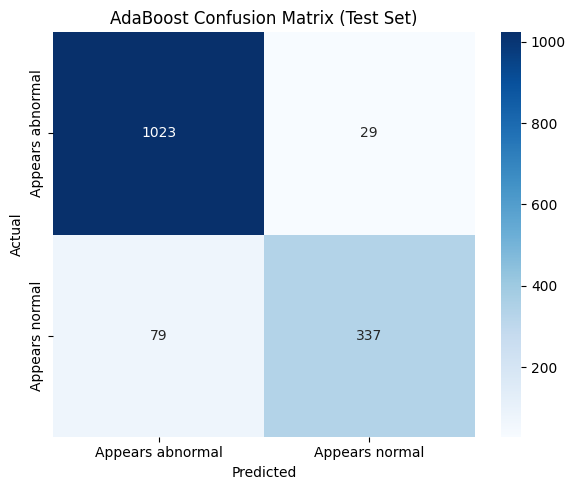


Final EfficientNet-B0 Test Loss: 0.4504 (CE: 0.3816, Dice: 0.5193), Final EfficientNet-B0 Test Accuracy: 0.8903

EfficientNet-B0 Test Precision (weighted): 0.8891
EfficientNet-B0 Test Recall (weighted): 0.8903
EfficientNet-B0 Test F1-score (weighted): 0.8869

EfficientNet-B0 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal     0.8960    0.9582    0.9260      1052
  Appears normal     0.8717    0.7188    0.7879       416

        accuracy                         0.8903      1468
       macro avg     0.8839    0.8385    0.8570      1468
    weighted avg     0.8891    0.8903    0.8869      1468



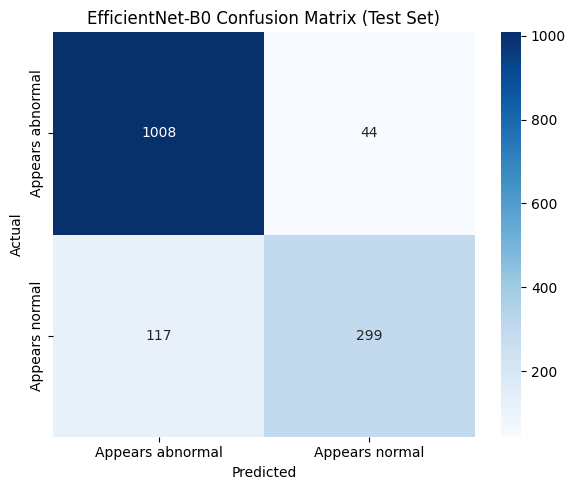

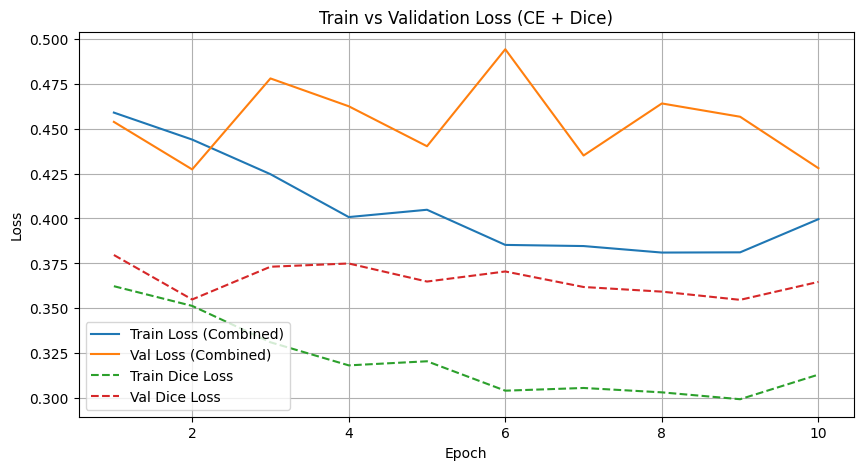

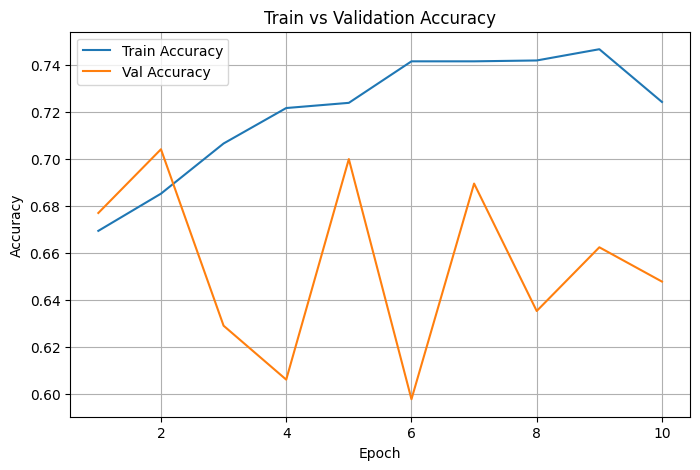


================ FINAL SUMMARY ================
Seed: 2622715460
Best EfficientNet-B0 Val Accuracy: 0.7042
EfficientNet-B0 Test Accuracy: 0.8903
EfficientNet-B0 Test Precision: 0.8891
EfficientNet-B0 Test Recall: 0.8903
EfficientNet-B0 Test F1-score: 0.8869
EfficientNet-B0 Test Dice Loss: 0.5193

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.7146
AdaBoost Test Accuracy: 0.9264
AdaBoost Test Precision: 0.9262
AdaBoost Test Recall: 0.9264
AdaBoost Test F1-score: 0.9249


In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import json
import joblib
import random
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import AdaBoostClassifier

import seaborn as sns


# ============================================================
# Fixed seed (single run)
# ============================================================
seed = 2622715460
print(f"\n########## SEED = {seed} ##########\n")

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# Device configuration
# ============================================================
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# Paths to train and test datasets
# ============================================================
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'
OUT_DIR = '/kaggle/working'


# ============================================================
# Image transformations
# ============================================================
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# Datasets
# ============================================================
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)


# ============================================================
# Split train_dataset into train_subset + val_subset (85/15)
# ============================================================
val_size = int(0.15 * len(train_dataset))

train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# ============================================================
# Save train / val indices (does not change any results)
# ============================================================
split_info = {
    "seed": seed,
    "val_fraction": 0.15,
    "classes": train_dataset.classes,
    "class_to_idx": train_dataset.class_to_idx,
    "train_indices": [int(i) for i in train_subset.indices],
    "val_indices": [int(i) for i in val_subset.indices],
    "train_files": [train_dataset.samples[i][0] for i in train_subset.indices],
    "val_files": [train_dataset.samples[i][0] for i in val_subset.indices],
}
with open(os.path.join(OUT_DIR, "split_indices_efficientnet.json"), "w") as f:
    json.dump(split_info, f)
print(f"Saved split indices: {len(train_subset.indices)} train / {len(val_subset.indices)} val")


# ============================================================
# Count samples per class within train_subset
# ============================================================
train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(
    train_targets
)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


# ============================================================
# Weighted Random Sampler
# ============================================================
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


# ============================================================
# DataLoaders
# ============================================================
train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# ============================================================
# Load pre-trained EfficientNet-B0
# ============================================================
efficientnet = models.efficientnet_b0(
    pretrained=True
)

num_classes = len(
    train_dataset.classes
)

efficientnet.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

efficientnet = efficientnet.to(device)


# ============================================================
# Dice Loss
# ============================================================
class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = probs.sum(dim=0) + targets_one_hot.sum(dim=0)

        dice_score = (2. * intersection + self.smooth) / (union + self.smooth)

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================
class CombinedLoss(nn.Module):

    def __init__(self, num_classes, ce_weight=0.5, dice_weight=0.5):
        super().__init__()
        self.ce_loss = nn.CrossEntropyLoss()
        self.dice_loss = DiceLoss(num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):
        ce = self.ce_loss(logits, targets)
        dice = self.dice_loss(logits, targets)
        total = self.ce_weight * ce + self.dice_weight * dice
        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)


# ============================================================
# Optimizer
# ============================================================
optimizer = optim.Adam(
    efficientnet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate EfficientNet-B0
# ============================================================
def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(outputs, labels)

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================
def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            all_preds.extend(predicted.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================
best_accuracy = 0.0

best_model_path = "EfficientNet_B0_seed2622715460.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


# ============================================================
# Lists for graphs
# ============================================================
train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# EfficientNet-B0 Training
# ============================================================
for epoch in range(max_epochs):

    efficientnet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = efficientnet(images)

        loss, ce, dice = criterion(outputs, labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(outputs, 1)

        total_train += labels.size(0)

        correct_train += (predicted == labels).sum().item()

    train_accuracy = correct_train / total_train

    n_batches = len(train_loader)

    train_loss = running_loss / n_batches
    train_ce = running_ce / n_batches
    train_dice = running_dice / n_batches

    # ---------------- Validation ----------------
    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        efficientnet,
        val_loader
    )

    # ---------------- Store values for graphs ----------------
    train_losses.append(train_loss)
    train_accs.append(train_accuracy)
    val_losses.append(val_loss)
    val_accs.append(val_accuracy)
    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)
    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    # ---------------- Print epoch results ----------------
    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, '
        f'Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, '
        f'Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # ---------------- Early stopping logic ----------------
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(efficientnet.state_dict(), best_model_path)

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at '
            f'epoch {epoch+1}. '
            f'Best Val Accuracy: {best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best EfficientNet-B0 model
# ============================================================
best_efficientnet_model = models.efficientnet_b0(
    pretrained=False
)

best_efficientnet_model.classifier[1] = nn.Linear(
    efficientnet.classifier[1].in_features,
    num_classes
)

best_efficientnet_model = best_efficientnet_model.to(device)

best_efficientnet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# Save final trained EfficientNet-B0 weights (does not change results)
# ============================================================
final_weights_path = os.path.join(OUT_DIR, "efficientnet_b0_final_weights.pth")
torch.save({
    "state_dict": best_efficientnet_model.state_dict(),
    "num_classes": num_classes,
    "classes": train_dataset.classes,
    "class_to_idx": train_dataset.class_to_idx,
    "best_val_accuracy": best_accuracy,
    "seed": seed,
    "input_size": 224,
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
}, final_weights_path)
print("Saved model weights ->", final_weights_path)


# ============================================================
# ADABOOST
# EfficientNet-B0 Feature Extraction + AdaBoost
# ============================================================
def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in tqdm(loader, desc="Extracting Features"):

            images = images.to(device)

            # Extract features before classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(x, (1, 1))

            # Flatten
            x = torch.flatten(x, 1)

            features.extend(x.cpu().numpy())

            labels_list.extend(labels.numpy())

    return (
        np.array(features),
        np.array(labels_list)
    )


print("\nExtracting EfficientNet-B0 features...")

train_features, train_labels = extract_features(best_efficientnet_model, train_loader)

val_features, val_labels = extract_features(best_efficientnet_model, val_loader)

test_features, test_labels = extract_features(best_efficientnet_model, test_loader)

print("\nFeature shape:", train_features.shape)


# ============================================================
# Train AdaBoost
# ============================================================
adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=seed
)

print("\nTraining AdaBoost...")

adaboost_model.fit(train_features, train_labels)

# Save trained AdaBoost (does not change results)
adaboost_path = os.path.join(OUT_DIR, "adaboost_efficientnet_final.joblib")
joblib.dump(adaboost_model, adaboost_path)
print("Saved AdaBoost ->", adaboost_path)


# ============================================================
# AdaBoost Validation
# ============================================================
adaboost_val_preds = adaboost_model.predict(val_features)

adaboost_val_accuracy = np.mean(adaboost_val_preds == val_labels)

print(f"\nAdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}")


# ============================================================
# AdaBoost Test Predictions
# ============================================================
adaboost_test_preds = adaboost_model.predict(test_features)

adaboost_test_accuracy = np.mean(adaboost_test_preds == test_labels)

print(f"AdaBoost Test Accuracy: {adaboost_test_accuracy:.4f}")


# ============================================================
# AdaBoost Metrics
# ============================================================
class_names = train_dataset.classes

adaboost_accuracy = np.mean(adaboost_test_preds == test_labels)

adaboost_precision = precision_score(
    test_labels, adaboost_test_preds, average='weighted', zero_division=0
)

adaboost_recall = recall_score(
    test_labels, adaboost_test_preds, average='weighted', zero_division=0
)

adaboost_f1 = f1_score(
    test_labels, adaboost_test_preds, average='weighted', zero_division=0
)

print("\n---------------- AdaBoost Metrics ----------------")
print(f"AdaBoost Test Accuracy: {adaboost_accuracy:.4f}")
print(f"AdaBoost Test Precision (weighted): {adaboost_precision:.4f}")
print(f"AdaBoost Test Recall (weighted): {adaboost_recall:.4f}")
print(f"AdaBoost Test F1-score (weighted): {adaboost_f1:.4f}")


# ============================================================
# AdaBoost Classification Report
# ============================================================
print("\nAdaBoost Per-class report:")

print(
    classification_report(
        test_labels,
        adaboost_test_preds,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# AdaBoost Confusion Matrix
# ============================================================
adaboost_cm = confusion_matrix(test_labels, adaboost_test_preds)

plt.figure(figsize=(6, 5))

sns.heatmap(
    adaboost_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('AdaBoost Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()


# ============================================================
# EFFICIENTNET-B0 TEST EVALUATION
# ============================================================
test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_efficientnet_model,
    test_loader
)

print(
    f'\nFinal EfficientNet-B0 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, '
    f'Dice: {test_dice:.4f}), '
    f'Final EfficientNet-B0 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# EfficientNet-B0 Test Metrics
# ============================================================
true_labels, pred_labels = get_predictions(best_efficientnet_model, test_loader)

precision = precision_score(true_labels, pred_labels, average='weighted', zero_division=0)

recall = recall_score(true_labels, pred_labels, average='weighted', zero_division=0)

f1 = f1_score(true_labels, pred_labels, average='weighted', zero_division=0)

print(f'\nEfficientNet-B0 Test Precision (weighted): {precision:.4f}')
print(f'EfficientNet-B0 Test Recall (weighted): {recall:.4f}')
print(f'EfficientNet-B0 Test F1-score (weighted): {f1:.4f}')


# ============================================================
# EfficientNet-B0 Classification Report
# ============================================================
print('\nEfficientNet-B0 Per-class report:')

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# EfficientNet-B0 Confusion Matrix
# ============================================================
cm = confusion_matrix(true_labels, pred_labels)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('EfficientNet-B0 Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_losses, label='Train Loss (Combined)')
plt.plot(epochs_range, val_losses, label='Val Loss (Combined)')
plt.plot(epochs_range, train_dice_losses, '--', label='Train Dice Loss')
plt.plot(epochs_range, val_dice_losses, '--', label='Val Dice Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train vs Validation Loss (CE + Dice)')
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================
plt.figure(figsize=(8, 5))

plt.plot(epochs_range, train_accs, label='Train Accuracy')
plt.plot(epochs_range, val_accs, label='Val Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================
print('\n================ FINAL SUMMARY ================')
print(f'Seed: {seed}')
print(f'Best EfficientNet-B0 Val Accuracy: {best_accuracy:.4f}')
print(f'EfficientNet-B0 Test Accuracy: {test_accuracy:.4f}')
print(f'EfficientNet-B0 Test Precision: {precision:.4f}')
print(f'EfficientNet-B0 Test Recall: {recall:.4f}')
print(f'EfficientNet-B0 Test F1-score: {f1:.4f}')
print(f'EfficientNet-B0 Test Dice Loss: {test_dice:.4f}')

print('\n---------------- AdaBoost ----------------')
print(f'AdaBoost Validation Accuracy: {adaboost_val_accuracy:.4f}')
print(f'AdaBoost Test Accuracy: {adaboost_accuracy:.4f}')
print(f'AdaBoost Test Precision: {adaboost_precision:.4f}')
print(f'AdaBoost Test Recall: {adaboost_recall:.4f}')
print(f'AdaBoost Test F1-score: {adaboost_f1:.4f}')

# Savingg

In [16]:

import os
import json
import csv
import shutil
import hashlib
import platform
import zipfile
from pathlib import Path
from datetime import datetime, timezone

import torch
import torchvision
import numpy as np
import sklearn
import joblib

# ============================================================
# 1. CONFIGURATION
# ============================================================
SEED = 2622715460

OUT_DIR = "/kaggle/working"
TRAIN_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "train")
TEST_DIR = os.path.join(OUT_DIR, "PCOSGen-train", "test")

SPLIT_FILE = os.path.join(
    OUT_DIR, "split_indices_efficientnet.json"
)
MODEL_FILE = os.path.join(
    OUT_DIR, "efficientnet_b0_final_weights.pth"
)
ADABOOST_FILE = os.path.join(
    OUT_DIR, "adaboost_efficientnet_final.joblib"
)
BEST_CHECKPOINT = os.path.join(
    OUT_DIR, "EfficientNet_B0_seed2622715460.pkl"
)

PACKAGE_NAME = f"EfficientNetB0_AdaBoost_Seed_{SEED}"
PACKAGE_DIR = os.path.join(OUT_DIR, PACKAGE_NAME)
ZIP_FILE = os.path.join(OUT_DIR, PACKAGE_NAME + ".zip")

# ============================================================
# 2. CHECK REQUIRED FILES
# ============================================================
for path in [SPLIT_FILE, MODEL_FILE, ADABOOST_FILE]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Run the training and model-saving cells first."
        )

# ============================================================
# 3. LOAD AND VALIDATE SAVED SPLIT
# ============================================================
with open(SPLIT_FILE, "r", encoding="utf-8") as f:
    split_info = json.load(f)

if int(split_info["seed"]) != SEED:
    raise ValueError(
        f"Seed mismatch: found {split_info['seed']}, expected {SEED}"
    )

for split_name in ["train", "val"]:
    indices = split_info[f"{split_name}_indices"]
    paths = split_info[f"{split_name}_files"]

    if len(indices) != len(paths):
        raise ValueError(
            f"{split_name}: index count does not match image-path count."
        )

if set(split_info["train_indices"]) & set(split_info["val_indices"]):
    raise ValueError("Train and validation indices overlap.")

# ============================================================
# 4. CREATE PACKAGE FOLDERS
# ============================================================
if os.path.exists(PACKAGE_DIR):
    shutil.rmtree(PACKAGE_DIR)

for folder in ["splits", "models", "config", "metadata"]:
    os.makedirs(
        os.path.join(PACKAGE_DIR, folder),
        exist_ok=True
    )

# ============================================================
# 5. SAVE TRAIN/VALIDATION INDICES AND IMAGE NAMES
# ============================================================
shutil.copy2(
    SPLIT_FILE,
    os.path.join(PACKAGE_DIR, "splits", "split_indices.json")
)

split_csv = os.path.join(
    PACKAGE_DIR, "splits", "split_images.csv"
)

with open(
    split_csv, "w", newline="", encoding="utf-8"
) as f:
    writer = csv.writer(f)
    writer.writerow([
        "split",
        "dataset_index",
        "image_name",
        "image_path",
        "class_name"
    ])

    for split_name in ["train", "val"]:
        indices = split_info[f"{split_name}_indices"]
        image_paths = split_info[f"{split_name}_files"]

        for index, image_path in zip(indices, image_paths):
            writer.writerow([
                split_name,
                index,
                os.path.basename(image_path),
                image_path,
                os.path.basename(os.path.dirname(image_path))
            ])

print("Training images:", len(split_info["train_indices"]))
print("Validation images:", len(split_info["val_indices"]))
print("Saved image names and split indices.")

# ============================================================
# 6. COPY EFFICIENTNET-B0 AND ADABOOST MODELS
# ============================================================
shutil.copy2(
    MODEL_FILE,
    os.path.join(
        PACKAGE_DIR, "models",
        "efficientnet_b0_final_weights.pth"
    )
)

shutil.copy2(
    ADABOOST_FILE,
    os.path.join(
        PACKAGE_DIR, "models",
        "adaboost_efficientnet_final.joblib"
    )
)

if os.path.isfile(BEST_CHECKPOINT):
    shutil.copy2(
        BEST_CHECKPOINT,
        os.path.join(
            PACKAGE_DIR, "models",
            "best_efficientnet_b0_checkpoint.pkl"
        )
    )
    print("Best EfficientNet-B0 checkpoint included.")
else:
    print(
        "Note: Best checkpoint not found at expected path. "
        "Final model weights are included."
    )

# ============================================================
# 7. LOAD FINAL MODEL CONFIGURATION
# ============================================================
checkpoint = torch.load(
    MODEL_FILE,
    map_location="cpu",
    weights_only=True
)

# ============================================================
# 8. SAVE MODEL AND TRAINING CONFIGURATION
# ============================================================
config = {
    "project": "PCOS ultrasound image classification",
    "architecture": "EfficientNet-B0 + AdaBoost",
    "seed": SEED,

    "dataset_split": {
        "method": "random_split",
        "validation_fraction": split_info["val_fraction"],
        "train_count": len(split_info["train_indices"]),
        "validation_count": len(split_info["val_indices"]),
        "indices_file": "splits/split_indices.json",
        "image_manifest": "splits/split_images.csv"
    },

    "classes": split_info["classes"],
    "class_to_idx": split_info["class_to_idx"],

    "efficientnet_b0": {
        "weights_file": "models/efficientnet_b0_final_weights.pth",
        "num_classes": checkpoint["num_classes"],
        "best_validation_accuracy": checkpoint["best_val_accuracy"],
        "input_size": checkpoint["input_size"],
        "normalization_mean": checkpoint["normalize_mean"],
        "normalization_std": checkpoint["normalize_std"],
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "batch_size": 64,
        "max_epochs": 50,
        "early_stopping_patience": 8,
        "loss": "0.5 * CrossEntropyLoss + 0.5 * DiceLoss",
        "sampler": "WeightedRandomSampler",
        "training_augmentations": [
            "Resize(224, 224)",
            "RandomHorizontalFlip",
            "RandomRotation(20)"
        ]
    },

    "adaboost": {
        "model_file": "models/adaboost_efficientnet_final.joblib",
        "n_estimators": 100,
        "learning_rate": 1.0,
        "random_state": SEED
    },

    "original_kaggle_paths": {
        "train": TRAIN_DIR,
        "test": TEST_DIR
    },

    "note": (
        "Original paths refer to Kaggle. Update paths on another "
        "computer and preserve dataset class ordering."
    )
}

with open(
    os.path.join(PACKAGE_DIR, "config", "model_config.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(config, f, indent=4)

# ============================================================
# 9. SAVE SOFTWARE AND HARDWARE INFORMATION
# ============================================================
environment = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "numpy_version": np.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

with open(
    os.path.join(PACKAGE_DIR, "metadata", "environment.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(environment, f, indent=4)

# ============================================================
# 10. CREATE DATASET MANIFESTS WITH SHA256 HASHES
# ============================================================
def create_manifest(dataset_dir, output_csv):
    if not os.path.isdir(dataset_dir):
        print("WARNING: Dataset directory not found:", dataset_dir)
        return

    with open(
        output_csv, "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.writer(f)
        writer.writerow([
            "relative_path",
            "class_name",
            "file_size_bytes",
            "sha256"
        ])

        for path in sorted(Path(dataset_dir).rglob("*")):
            if not path.is_file():
                continue

            relative_path = path.relative_to(
                dataset_dir
            ).as_posix()

            parts = Path(relative_path).parts
            class_name = parts[0] if len(parts) > 1 else ""

            digest = hashlib.sha256()

            with open(path, "rb") as image_file:
                for chunk in iter(
                    lambda: image_file.read(1024 * 1024), b""
                ):
                    digest.update(chunk)

            writer.writerow([
                relative_path,
                class_name,
                path.stat().st_size,
                digest.hexdigest()
            ])

create_manifest(
    TRAIN_DIR,
    os.path.join(
        PACKAGE_DIR, "metadata",
        "train_dataset_manifest.csv"
    )
)

create_manifest(
    TEST_DIR,
    os.path.join(
        PACKAGE_DIR, "metadata",
        "test_dataset_manifest.csv"
    )
)

# ============================================================
# 11. README FOR RESEARCHERS
# ============================================================
readme = f"""
{PACKAGE_NAME}
{'=' * len(PACKAGE_NAME)}

CONTENTS
--------
splits/split_indices.json
    Saved train/validation indices, image paths, seed and classes.

splits/split_images.csv
    Split, index, image name, image path and class name.

models/efficientnet_b0_final_weights.pth
    Trained EfficientNet-B0 weights and configuration.

models/adaboost_efficientnet_final.joblib
    Trained AdaBoost classifier.

models/best_efficientnet_b0_checkpoint.pkl
    Best validation checkpoint, if available.

config/model_config.json
    Model, preprocessing and training configuration.

metadata/environment.json
    Python, library, platform and CUDA information.

metadata/train_dataset_manifest.csv
metadata/test_dataset_manifest.csv
    Dataset paths, file sizes and SHA-256 hashes.

REPRODUCTION
------------
1. Obtain the same dataset version and labels.
2. Verify the dataset files using the SHA-256 manifests.
3. Restore the saved train/validation split.
4. Preserve ImageFolder class ordering and preprocessing.
5. Load the saved models for inference.
6. Use the original notebook and dataset to retrain the models.

IMPORTANT
---------
The dataset and complete training notebook are not included.
Absolute paths refer to the original Kaggle environment.
The notebook stores the evaluation results separately.
A matching seed alone does not guarantee identical results
across different hardware or software versions.
"""

with open(
    os.path.join(PACKAGE_DIR, "README.txt"),
    "w", encoding="utf-8"
) as f:
    f.write(readme.strip() + "\n")

# ============================================================
# 12. CREATE ZIP
# ============================================================
if os.path.exists(ZIP_FILE):
    os.remove(ZIP_FILE)

with zipfile.ZipFile(
    ZIP_FILE,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(Path(PACKAGE_DIR).rglob("*")):
        if path.is_file():
            archive.write(
                path,
                arcname=path.relative_to(OUT_DIR).as_posix()
            )

# ============================================================
# 13. VERIFY ZIP
# ============================================================
with zipfile.ZipFile(ZIP_FILE, "r") as archive:
    bad_file = archive.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP verification failed: {bad_file}"
        )

    print("\nZIP CONTENTS:")
    for name in archive.namelist():
        print(" -", name)

print("\nZIP CREATED AND VERIFIED SUCCESSFULLY")
print("File:", ZIP_FILE)
print("Size: {:.2f} MB".format(
    os.path.getsize(ZIP_FILE) / (1024 ** 2)
))


Training images: 2720
Validation images: 480
Saved image names and split indices.
Best EfficientNet-B0 checkpoint included.

ZIP CONTENTS:
 - EfficientNetB0_AdaBoost_Seed_2622715460/README.txt
 - EfficientNetB0_AdaBoost_Seed_2622715460/config/model_config.json
 - EfficientNetB0_AdaBoost_Seed_2622715460/metadata/environment.json
 - EfficientNetB0_AdaBoost_Seed_2622715460/metadata/test_dataset_manifest.csv
 - EfficientNetB0_AdaBoost_Seed_2622715460/metadata/train_dataset_manifest.csv
 - EfficientNetB0_AdaBoost_Seed_2622715460/models/adaboost_efficientnet_final.joblib
 - EfficientNetB0_AdaBoost_Seed_2622715460/models/best_efficientnet_b0_checkpoint.pkl
 - EfficientNetB0_AdaBoost_Seed_2622715460/models/efficientnet_b0_final_weights.pth
 - EfficientNetB0_AdaBoost_Seed_2622715460/splits/split_images.csv
 - EfficientNetB0_AdaBoost_Seed_2622715460/splits/split_indices.json

ZIP CREATED AND VERIFIED SUCCESSFULLY
File: /kaggle/working/EfficientNetB0_AdaBoost_Seed_2622715460.zip
Size: 29.05 MB
